# EEGNet Experiment

EEGNet baseline for Congruent vs Incongruent Pure using raw EEG epochs. This notebook follows the refactored path/task pattern from `09_experiment_template.ipynb` and saves metrics, histories, and figures under its analysis directory.


In [ ]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
import torch

NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import BinaryTaskConfig, RawEpochSpec, detect_project_paths, load_raw_epoch_dataset
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    plot_fold_metrics,
    plot_torch_history,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available; using CPU.")

from br_analysis.torch_models import EEGNet

Source directory: /content/drive/MyDrive/TFG_Nils_2026/03_Codi
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using CUDA GPU: Tesla T4


## Task And Output Paths


In [29]:
TASK_TAG = "c_vs_ip_eegnet"
paths = detect_project_paths("c_vs_i_eegnet", in_colab=IN_COLAB)
SELECTED_SUBJECTS_CSV = paths.analysis_root / "01_exploracio" / "tables" / "subjectes_seleccionats.csv"
MAX_SUBJECTS = 24

task = BinaryTaskConfig(
    name=TASK_TAG,
    class_0="Congruent",
    class_1="Incongruent_Pur",
    event_codes={"Congruent": [1, 2], "Incongruent_Pur": [3, 4, 5, 6]},
    selected_subjects_csv=SELECTED_SUBJECTS_CSV,
    max_subjects=MAX_SUBJECTS,
    undersample_classes=True,
    analysis_window=(0.0, 1.5),
    random_seed=RANDOM_SEED,
)

print(f"Projecte: {paths.project_dir}")
print(f"Dades: {paths.data_dir}")
print(f"Resultats: {paths.analysis_dir}")
print(f"Tables: {paths.tables_dir}")
print(f"Figures: {paths.figures_dir}")

Projecte: /content/drive/MyDrive/TFG_Nils_2026
Dades: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs
Resultats: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet
Tables: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet/tables
Figures: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet/figures


## Load Raw Epochs


Subjectes seleccionats a carregar: 22
Mostres totals: 5616 | Congruent=2808 | Incongruent_Pur=2808
Subjectes carregats: 22 | Canals: 60
X shape: (5616, 60, 192)  (trials, channels, times)
Classes: [2808 2808]


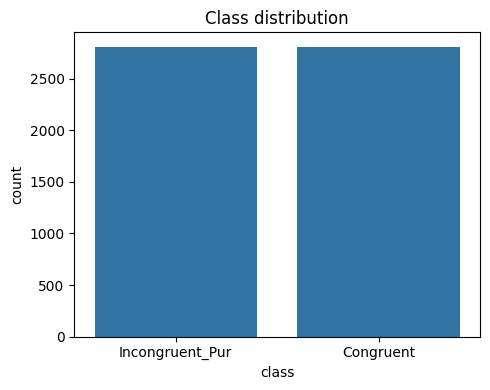

In [30]:
spec = RawEpochSpec(
    picks=None,
    bandpass=(1.0, 40.0),
    resample_sfreq=128.0,
)
dataset = load_raw_epoch_dataset(paths, task, spec)
X = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = dataset.subject_ids[0]  # Canvia aquest valor per entrenar/avaluar un altre subjecte.
ch_names = list(dataset.channel_names)
times = dataset.times

print(f"X shape: {X.shape}  (trials, channels, times)")
print(f"Classes: {np.bincount(y)}")

class_df = pd.DataFrame({"class": np.where(y == 0, task.class_0, task.class_1)})
plt.figure(figsize=(5, 4))
sns.countplot(data=class_df, x="class")
plt.title("Class distribution")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"class_distribution_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## Train EEGNet


In [31]:
from functools import partial

n_channels = X.shape[1]
n_times = X.shape[2]


def make_model():
    return EEGNet(
        n_channels=n_channels,
        n_times=n_times,
        n_classes=2,
        F1=8,
        D=2,
        F2=16,
        kernel_length=64,
        dropout=0.5,
    )


train_cfg = TorchTrainConfig(
    epochs=80,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=12,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

metrics, history = cross_validate_torch_model(X, y, make_model, train_cfg, subjects=subjects, subject_id=SUBJECT_ID)
metrics_path = paths.tables_dir / f"cv_metrics_{TASK_TAG}.csv"
history_path = paths.tables_dir / f"training_history_{TASK_TAG}.csv"
metrics.to_csv(metrics_path, index=False)
history.to_csv(history_path, index=False)
print(f"Saved metrics: {metrics_path}")
print(f"Saved history: {history_path}")
metrics

Fold 1: acc=0.581, bal_acc=0.581, auc=0.615
Fold 2: acc=0.586, bal_acc=0.586, auc=0.615
Fold 3: acc=0.581, bal_acc=0.581, auc=0.608
Fold 4: acc=0.577, bal_acc=0.577, auc=0.614
Fold 5: acc=0.570, bal_acc=0.570, auc=0.576
Saved metrics: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet/tables/cv_metrics_c_vs_ip_eegnet.csv
Saved history: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet/tables/training_history_c_vs_ip_eegnet.csv


,test_loss,test_acc,test_balanced_acc,test_auc,best_val_acc,epochs_ran,fold
0,0.671318,0.580961,0.580961,0.615231,0.609566,29,1
1,0.671987,0.585931,0.585907,0.615029,0.583982,25,2
2,0.675261,0.580588,0.580529,0.608214,0.581758,20,3
3,0.667486,0.577026,0.577063,0.614336,0.577308,22,4
4,0.691075,0.569902,0.569952,0.576135,0.601780,22,5


## Visualize Training


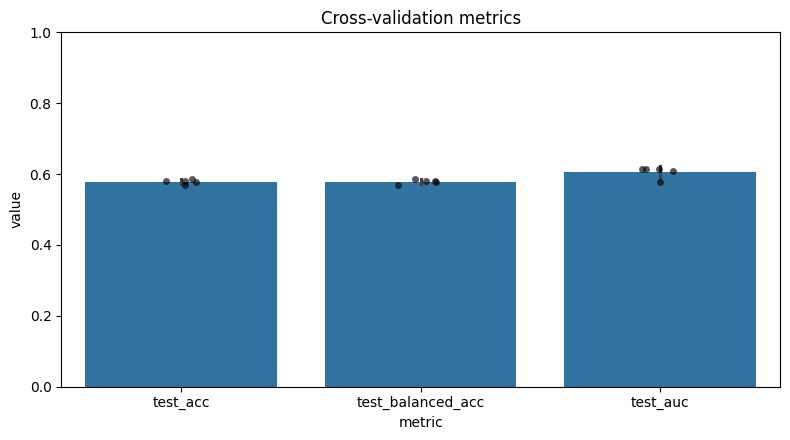

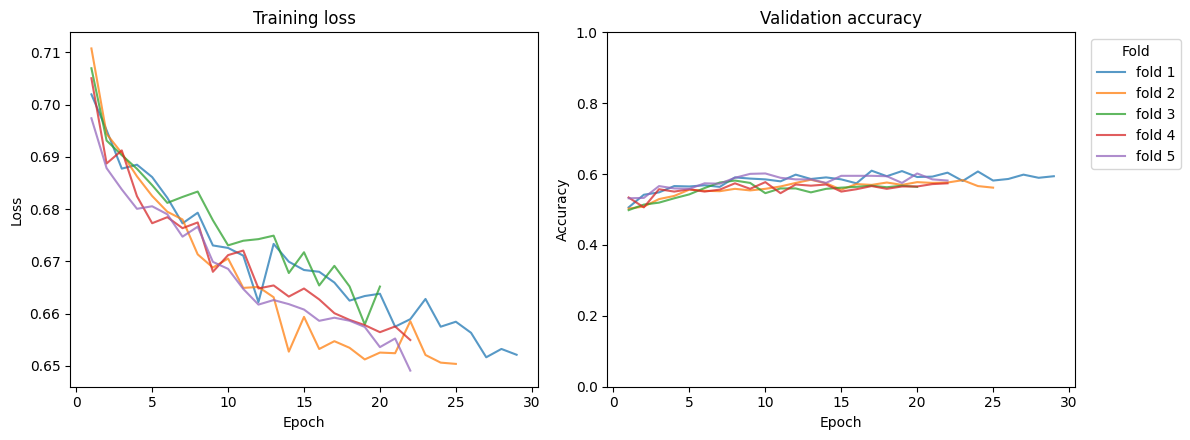

Saved summary: /content/drive/MyDrive/TFG_Nils_2026/04_Anàlisi/c_vs_i_eegnet/tables/summary_c_vs_ip_eegnet.csv


,metric,mean,std
0,test_loss,0.675425,0.009174
1,test_acc,0.578881,0.005937
2,test_balanced_acc,0.578882,0.005904
3,test_auc,0.605789,0.016829
4,best_val_acc,0.590879,0.013991
5,epochs_ran,23.600000,3.507136


In [32]:
plot_fold_metrics(metrics, output_file=paths.figures_dir / f"fold_metrics_{TASK_TAG}.png")
plot_torch_history(history, output_file=paths.figures_dir / f"training_history_{TASK_TAG}.png")

summary = metrics.drop(columns=["fold"]).agg(["mean", "std"]).T.reset_index().rename(columns={"index": "metric"})
summary_path = paths.tables_dir / f"summary_{TASK_TAG}.csv"
summary.to_csv(summary_path, index=False)
print(f"Saved summary: {summary_path}")
summary